<h1 style="text-align: center"> Automobile Fuel Efficiency Prediction & Interpretation </h1>
<h3 style="text-align: center; font-style: italic"> Garudapaksi Yusuf </h3>

---

The **Auto MPG Dataset** from **UCI Machine Learning Repository** provides an excellent foundation for analyzing the key technical factors that influence vehicle fuel efficiency. As fuel economy remains a critical consideration for manufacturers, regulators, and consumers alike, understanding which design attributes most strongly impact miles per gallon (MPG) is essential. This project combines feature analysis with statistical prediction—using machine learning models to uncover how variables such as engine displacement, horsepower, vehicle weight, and cylinder count contribute to fuel performance outcomes.

By applying regression models and interpretability techniques such as feature importance analysis and coefficient evaluation, the project aims to translate raw vehicle specifications into actionable engineering insights. Instead of treating the model as a black box, we leverage explainable machine learning methods to quantify the relative influence of each feature on MPG. The outcome is a data-driven framework that supports design optimization, highlights efficiency trade-offs, and enables informed decision-making in early-stage vehicle development.

---

## Section 1 | Initial Data Analysis

In [49]:
# import required libraries
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from feature_engine.imputation import DropMissingData
from feature_engine.preprocessing import MatchCategories
from pyampute.exploration.mcar_statistical_tests import MCARTest
from ucimlrepo import fetch_ucirepo

### Data Specification

*The first step in data analysis is to set out a full and detailed [specification](https://en.wikipedia.org/wiki/Data_preparation#Data_specification) of the format of each data field and what the entries mean. This especially take careful account of a full understanding of the information available, and any gaps, in the source data.*

#### Data Context

<div align="center">

| <div style="width:170px"> Category </div> | Description |
| --- | --- |
| Source URL | [University of California, Irvine (UCI) Machine Learning Repository: "Auto MPG"](https://archive-beta.ics.uci.edu/dataset/9/auto+mpg) |
| Original Source URL | [Department of Statistics, Carnegie Mellon University (CMU) StatLib Datasets: "cars"](https://lib.stat.cmu.edu/datasets/) |
| License | [Creative Commons Attribution 4.0 International](https://creativecommons.org/licenses/by/4.0/legalcode) |
| Creation Date | July 7, 1993 |
| Number of Instances | 398 |
| Number of Features | 7 |
| Data Types | Multivariate |
| Associated Tasks | Regression |
| Feature Types | Continuous, Categorical, Integer |


</div>

This dataset is a slightly modified version of the dataset provided in the StatLib library. In line with the use by Quinlan (1993) in predicting the attribute `mpg`, 8 of the original instances were removed because they had unknown values for the `mpg` attribute.

> The data concern city-cycle fuel consumption in miles per gallon, to be predicted in terms of 3 multi-valued discrete and 5 continuous attributes<sup>1</sup>.

<sup>1</sup> Quinlan, R. (1993). Combining Instance-Based and Model-Based Learning. *In Proceedings on the Tenth International Conference of Machine Learning*, 236-243, University of Massachusetts, Amherst: Morgan Kaufmann.

#### Data ETL

In [50]:
def data_etl(id):
    """Fetches data from the UCI repository and prepares it for analysis.
    
    Args:
        id (int): The identifier for the dataset to be fetched from the UCI repository.
    
    Returns:
        pd.DataFrame: A DataFrame containing the features and target variables of the dataset.
    """
    ucirepo_dotdict = fetch_ucirepo(id=id)

    features = ucirepo_dotdict.data.features
    target = ucirepo_dotdict.data.targets

    axis_columns = 1
    dataset = pd.concat([features, target], axis=axis_columns)

    return dataset

* *[Extract, transform, load (ETL)](https://en.wikipedia.org/wiki/Extract,_transform,_load) is a three-phase computing process where data is extracted from an input source, transformed (to the appropriate format), and loaded into an output data container—or in this case, a variable instance.*
* *Tabel berikut menampilkan 5 sampel baris data dari dataset sebagai contoh hasil ETL:*

In [51]:
# fetch dataset
id_auto_mpg = 9
data = pd.DataFrame(data_etl(id=id_auto_mpg))

# show dataset samples
n_samples = 5
data.sample(n_samples)

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
327,121.0,5,67.0,2950,19.9,80,2,36.4
113,155.0,6,107.0,2472,14.0,73,1,21.0
380,120.0,4,88.0,2160,14.5,82,3,36.0
364,350.0,8,105.0,3725,19.0,81,1,26.6
20,110.0,4,87.0,2672,17.5,70,2,25.0


* Setiap baris dalam dataframe merepresentasikan satu *instance* dari car samples.
* Sedangkan kolom dalam dataframe tersebut adalah *variabel* yang mewakili keragaman dari each samples.
    * Beberapa kolom berperan sebagai *feature*, yakni independent variable yang digunakan sebagai input dari suatu model machine learning, dan
    * Kolom pertama merupakan *target*, which is the variable that corresponds to the input data.
* *Untuk kolom `car_name` tidak ikut disertakan dalam proses fetching yang disediakan oleh UCI ML Repository, tetapi kolom ini dapat diakses dengan mengunduh langsung raw data pada [source url]((https://archive-beta.ics.uci.edu/dataset/9/auto+mpg)) dan membuka file `auto-mpg.data`*.

#### Data Dictionary

<div align="center">

| No. | Variable | Role | Type | Description | Units | Missing Values |
| --- | --- | --- | --- | --- | --- | --- |
| <center> 1 </center> | `mpg` | Target | Continuous | *Miles per gallon* | - | <center> No </center> |
| <center> 2 </center> | `displacement` | Feature | Continuous | *Engine displacement* | *cu. inches* | <center> No </center> |
| <center> 3 </center> | `cylinders` | Feature | Integer | *Number of cylinders* | - | <center> No </center> |
| <center> 4 </center> | `horsepower` | Feature | Continuous | *Horsepower* | *hp* | <center> Yes </center> |
| <center> 5 </center> | `weight` | Feature | Continuous | *Weight* | *lbs.* | <center> No </center> |
| <center> 6 </center> | `acceleration` | Feature | Continuous | *Time to accelerate from 0 to 60 miles per hour* | *sec.* | <center> No </center> |
| <center> 7 </center> | `model_year` | Feature | Integer | *Model year* | *modulo 100* | <center> No </center> |
| <center> 8 </center> | `origin` | Feature | Integer | *Origin of car (1: American, 2: European, 3: Japanese)* | - | <center> No </center> |
| <center> 9 </center> | `car_name` | ID | Categorical | *Car manufacturer & type (unique for each instance)* | - | <center> No </center> |

</div>

### Data Inspection

In [52]:
# perform initial inspection on dataset
pd.DataFrame({
    "dtype": data.dtypes,
    "sample": [data[column].unique() for column in data.columns],
    "min": [data[column].min() for column in data.columns],
    "max": [data[column].max() for column in data.columns],
    "duplicated": data.duplicated().sum(),
    "missing": data.isna().sum()
})

,dtype,sample,min,max,duplicated,missing
displacement,float64,"[307.0, 350.0, 318.0, 304.0, 302.0, 429.0, 454...",68.0,455.0,0,0
cylinders,int64,"[8, 4, 6, 3, 5]",3.0,8.0,0,0
horsepower,float64,"[130.0, 165.0, 150.0, 140.0, 198.0, 220.0, 215...",46.0,230.0,0,6
weight,int64,"[3504, 3693, 3436, 3433, 3449, 4341, 4354, 431...",1613.0,5140.0,0,0
acceleration,float64,"[12.0, 11.5, 11.0, 10.5, 10.0, 9.0, 8.5, 8.0, ...",8.0,24.8,0,0
model_year,int64,"[70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 8...",70.0,82.0,0,0
origin,int64,"[1, 3, 2]",1.0,3.0,0,0
mpg,float64,"[18.0, 15.0, 16.0, 17.0, 14.0, 24.0, 22.0, 21....",9.0,46.6,0,0


* Kolom `dtype` menunjukkan jenis tipe data yang ada dalam `data_train`, yang seluruhnya memiliki tipe `float` dan `int`:
    * Tipe data tersebut merepresentasikan random `sample` yang ditunjukkan pada tiap variabel. Semisal `mpg` yang berisikan bilangan desimal `17.5`.
    * `float` mengindikasikan variabel dengan tipe data numerical continuous, sedangkan `int` untuk tipe data numerical discrete.
        * The true nature of `weight` variable is conceptually *continuous*—even if recorded as whole numbers—since they varies smoothly in reality and the measurement resolution in this case is arbitrarily decided.
        * Perlu diperhatikan juga tipe data dari target `mpg` is at the *ratio* level; true zero exists for this variable, which represents the absence of any fuel efficiency.
        * Dan domain knowledge mengindikasikan untuk variabel `origin` memiliki **invalid data type** dan seharusnya bertipe [nominal](https://en.wikipedia.org/wiki/Level_of_measurement#Nominal_level).
* Tidak ada invalid data issue yang terdeteksi:
    * Rentang nilai yang ditunjukkan dari kolom `min` dan `max` secara domain knowledge menunjukkan nilai yang valid, wajar, dan sebenarnya dari car samples.
    * Ambil contoh pada kolom `displacement`, a car's engine displacement bisa berada pada rentang nilai `70.0` hingga `455.0` cubic inches.
* Proses data inspection juga meliputi deteksi terhadap `duplicated` & `missing` data:
    * Tidak ada duplicated data yang terdeteksi, sebagaimana ditunjukkan pada nilai kolom `duplicated` untuk seluruh variabel bernilai `0`, tetapi
    * Terdeteksi adanya **missing data** pada variabel `horsepower`:
        * Sebagaimana ditunjukkan pada nilai kolom `missing` untuk variabel `horsepower` bernilai `6`.
        * Missing data [reduces the representativeness of the sample](https://en.wikipedia.org/wiki/Missing_data#Techniques_of_dealing_with_missing_data) and can therefore distort inferences about the population.

#### Missing Data

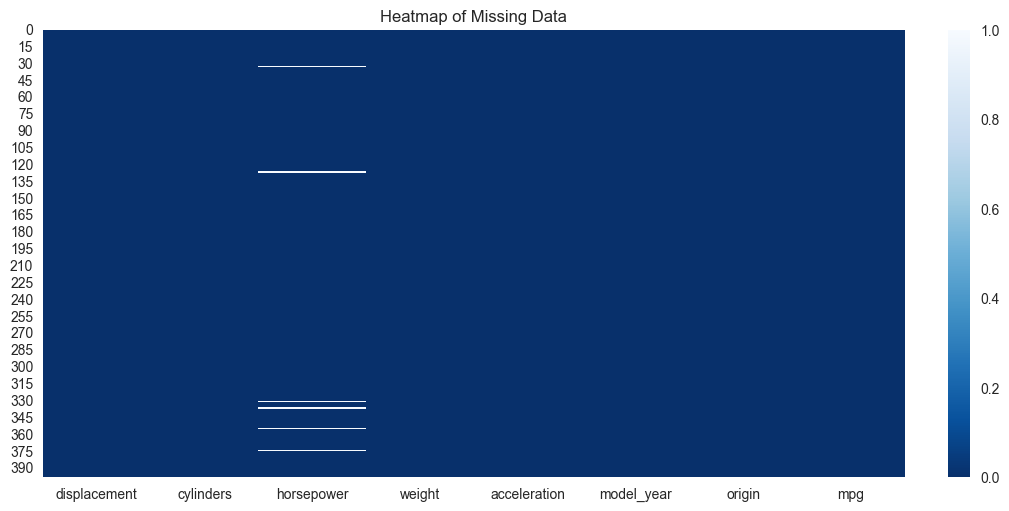

In [53]:
# visualize missing data pattern
width, height = 10, 5
plt.figure(figsize=(width, height), layout="constrained")

sns.heatmap(
    data.isna().sort_index(),
    cmap="Blues_r" # reverse color map for better visibility
)
plt.title("Heatmap of Missing Data")
plt.show()

*Heatmap di atas menunjukkan:*
* *Garis berwarna putih pada kolom `horsepower` yang merepresentasikan missing data pada kolom tersebut, dan*
* *Sumbu `y` menunjukkan lokasi (indeks) missing data tersebut dalam data.*

Dari visualisasi ini, dapat diinterpretasikan bahwa:
* Missing data terletak pada lokasi yang acak pada `horsepower`; dan
* Missing data terpisah satu sama lain, tidak berdekatan, berhimpitan maupun membentuk pola tertentu.

In [54]:
# slice missing data in dataset
data[data["horsepower"].isnull()]

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
32,98.0,4,NaN,2046,19.0,71,1,25.0
126,200.0,6,NaN,2875,17.0,74,1,21.0
330,85.0,4,NaN,1835,17.3,80,2,40.9
336,140.0,4,NaN,2905,14.3,80,1,23.6
354,100.0,4,NaN,2320,15.8,81,2,34.5
374,151.0,4,NaN,3035,20.5,82,1,23.0


*DataFrame di atas menunjukkan:*
* *Sampel dengan missing data pada `horsepower`,*
* *Nilai pada variabel lain dalam data dengan missing data tersebut, dan*
* *Indeks dari missing data dalam data.*

A priori, dapat disimpulkan bahwa:
* Tidak ada indikasi bahwa missing data tersebut are dependent on any other variable.
* Ambil contoh dari kolom `displacement`: missing data memiliki nilai `displacement` yang beragam.

In [55]:
# access p-value from Little's MCAR test results
mcar = MCARTest("little")
pvalue = mcar.little_mcar_test(data)

*Little's MCAR Test<sup>2</sup> adalah:*
* *Statistical hypothesis test untuk Missing Completely At Random (MCAR).*
    * *Null hypothesis: data is MCAR*
    * *Alternative hypothesis: data is not MCAR*
* *Metode yang digunakan adalah chi-square test on the entire data; membandingkan kelompok data dengan missing value terhadap kelompok data tanpa missing value to determine if there is a significant relationship between the two groups.*

<sup>2</sup> Little, R. J. A. (1988). A Test of Missing Completely at Random for Multivariate Data with Missing Values. *Journal of the American Statistical Association, 83*(404), 1198–1202. https://doi.org/10.1080/01621459.1988.10478722

In [56]:
# evaluate Little's MCAR test results
significance_level = 0.05
decision = "Reject H0" if pvalue <= significance_level else "Accept H0"

df_mcar = pd.DataFrame({
    "pvalue": [pvalue],
    "decision": [decision]
}, index=["result"])
df_mcar.transpose()

,result
pvalue,0.313475
decision,Accept H0


* Hasil observasi secara visual dan tabular di atas memberikan inferensi bahwa missing data tersebut adalah MCAR.
* When data is MCAR, there is absolutely no relationship between the data missing and any other values, observed or missing, within the data.
    * In other words, those missing data points are a random subset of the data.
    * There is nothing systematic going on that makes some data more likely to be missing than other.
* If values for observations are missing completely at random, then disregarding those cases would not bias the inferences made.

In [57]:
# discard missing data from dataset
dropper = DropMissingData()
data_dropped = pd.DataFrame(
    dropper.fit_transform(data),
    columns=dropper.get_feature_names_out()
)

* *Transformation yang digunakan pada `data_train` [juga diterapkan pada subsequent datasets](https://scikit-learn.org/stable/common_pitfalls.html#inconsistent-preprocessing), whether it's `data_test` or data in a production system.*
* *Discarding the missing data uses `DropMissingData()` transformer, karena transformer ini compatible dengan Scikit-learn pipeline yang akan digunakan pada bagian-bagian berikutnya.*

#### Invalid Data Type

In [58]:
# encode selected variables in dataset to Pandas' "categorical" data type
unmatched_variable = "origin"
matcher = MatchCategories(
    unmatched_variable,
    ignore_format=True # allow transformer on variables with non-string data type (e.g., numeric)
)
data_cleaned = pd.DataFrame(
    matcher.fit_transform(data_dropped),
    columns=matcher.get_feature_names_out()
)

Variabel `origin` dengan tipe data nominal juga merupakan bagian dari tipe data kategorikal, sehingga `MatchCategories()` transformer dapat digunakan untuk mengubah tipe data variabel tersebut.

#### Inspection Summary

In [59]:
# perform final inspection on cleaned dataset
pd.DataFrame({
    "dtype": data_cleaned.dtypes,
    "missing": data_cleaned.isna().sum()
})

,dtype,missing
displacement,float64,0
cylinders,int64,0
horsepower,float64,0
weight,int64,0
acceleration,float64,0
model_year,int64,0
origin,category,0
mpg,float64,0


* Variabel `origin` yang sebelumnya bertipe integer berhasil dikonversi ke tipe data kategorikal yang sesuai, dan
* Missing data succesfully dropped from the `data_train`.

---

## Section 2 | Exploratory Data Analysis

In [60]:
# import required libraries
import numpy as np
import statsmodels.api as sm
from dython.nominal import associations
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor

### Train-Test Split

*The train-test split is a technique for evaluating the performance of a machine learning algorithm. The procedure involves taking a dataset and dividing it into two subsets:*
1. *Train dataset berperan untuk melatih parameter dalam pemodelan —dan akan menjadi fokus analisis on this section—, sedangkan*
2. *Test dataset digunakan untuk mengevaluasi performa model tersebut pada unseen data, ensuring it generalizes well to new examples.*

In [61]:
def inspect_dimensionality(dataset, train, test):
    """Performs dimensionality analysis of the dataset and its train-test subsets.

    Args:
        dataset (pd.DataFrame): The original dataset.
        train (pd.DataFrame): The training subset of the dataset.
        test (pd.DataFrame): The testing subset of the dataset.
        
    Returns:
        pd.DataFrame: A DataFrame summarizing the number of rows, row ratio, 
        and number of columns for the dataset and its subsets.
    """
    shape_row, shape_column = 0, 1
    dimensionality_summary = pd.DataFrame({
        "row_n": [dataset.shape[shape_row], train.shape[shape_row], test.shape[shape_row]],
        "row_ratio": [
            dataset.shape[shape_row] / dataset.shape[shape_row],
            train.shape[shape_row] / dataset.shape[shape_row],
            test.shape[shape_row] / dataset.shape[shape_row]
        ],
        "column": [dataset.shape[shape_column], train.shape[shape_column], test.shape[shape_column]]
    }, index=["dataset", "train", "test"])
    
    return dimensionality_summary

In [62]:
# set random number generator instance
seed = 42
rng = np.random.RandomState(seed)

*Some scikit-learn `sklearn` objects are [inherently random](https://scikit-learn.org/stable/common_pitfalls.html#controlling-randomness). The randomness of these objects is controlled via their `random_state` parameter.*
* *In order to obtain reproducible (i.e. constant) results across multiple executions of this project, the recommended way is to declare an `rng` variable at the top of the project, and pass it down to any object that accepts a `random_state` parameter.*
* *Random seed yang digunakan secara arbitrary dalam project ini adalah [42](https://en.wikipedia.org/wiki/42_(number)).*

In [63]:
# split dataset to random train and test subsets
train, test = train_test_split(data_cleaned, random_state=rng)
data_train, data_test = pd.DataFrame(train), pd.DataFrame(test)

# perform dimensionality analysis on dataset and its subsets
inspect_dimensionality(data_cleaned, data_train, data_test)

,row_n,row_ratio,column
dataset,392,1.00,8
train,294,0.75,8
test,98,0.25,8


Tabel di atas mendeskripsikan dimensionality dari Auto MPG dataset setelah splitting dilakukan menjadi train dan test subsets:
* Keseluruhan dataset terdiri dari `392` baris dan `8` kolom.
* `train_test_split` membagi `data` tersebut menjadi sepasang `data_train` dan `data_test`.
    * Jumlah baris dalam dataset dibagi menjadi `~0.75/75%` untuk data train dan `~0.25/25%` untuk data test, sesuai default parameter.
    * Splitting ini hanya membagi tiap baris/observasi, sehingga jumlah kolom/variabel tidak berubah.

### Univariate EDA

*Univariate analysis is the simplest form of data analysis, focusing on describing and summarizing a single variable at a time. It analyzes the distribution, central tendency (mean, median, mode), and dispersion (range, variance) to identify patterns, outliers, and data characteristics, rather than examining relationships between variables.*

#### Descriptive Statistics

In [64]:
# subset numerical variables from train set
numerical_train = data_train.select_dtypes("number")

# generate simple descriptive statistics for numerical variables
percentiles = [0.5]
decimals = 2
numerical_train.describe(percentiles).round(decimals)

,displacement,cylinders,horsepower,weight,acceleration,model_year,mpg
count,294.00,294.00,294.00,294.00,294.00,294.00,294.00
mean,195.48,5.47,104.47,2971.83,15.51,76.14,23.69
std,104.66,1.71,38.60,841.77,2.86,3.65,8.01
min,70.00,3.00,46.00,1613.00,8.00,70.00,9.00
50%,151.00,4.00,92.50,2781.50,15.40,76.00,23.00
max,455.00,8.00,230.00,5140.00,24.80,82.00,46.60


*The exact numerical statistics for `numerical_variables` are provided above in tabular format.*
* *`count` refers to the number of non-null values for each columns (similar with `Row/Instance` values in [Section 1: Data Inspection](#data-inspection)),*
* *`mean` measures the [average](https://en.wikipedia.org/wiki/Arithmetic_mean) of the values over each columns,*
* *`std` represents the [standard deviation](https://en.wikipedia.org/wiki/Standard_deviation) for each variables,*
* *`min` and `max` are the minimum and maximum of the values in each columns, respectively, and*
* *`50%` is the corresponding [percentile](https://en.wikipedia.org/wiki/Percentile)—also known as the [median](https://en.wikipedia.org/wiki/Median).*

Terdeteksi adanya perbedaan rentang nilai atau [**order of magnitude**](https://en.wikipedia.org/wiki/Order_of_magnitude) antar variabel numerikal:
* Mulai dari rentang satuan `8.00` pada variabel `acceleration` hingga ribuan `5140.00` pada variabel `weight`.
* Keragaman nilai ini may pose several problems in machine learning:
    * In Linear Regression models, the scale of variables used to estimate the output matters. Linear models are of the type $y = wx + b$, where the regression coefficient $w$ represents the expected change in $y$ for a one unit change in $x$ (the predictor).
    * Thus, the magnitude of $w$ is partly determined by the magnitude of the units being used for $x$. If $x$ is a mass variable, just changing the scale from pounds to grams will cause a change in the magnitude of the coefficient.
* In addition, nilai numerik dari Auto MPG train set berada pada rentang nilai positif (> 0).

#### Visual Analysis

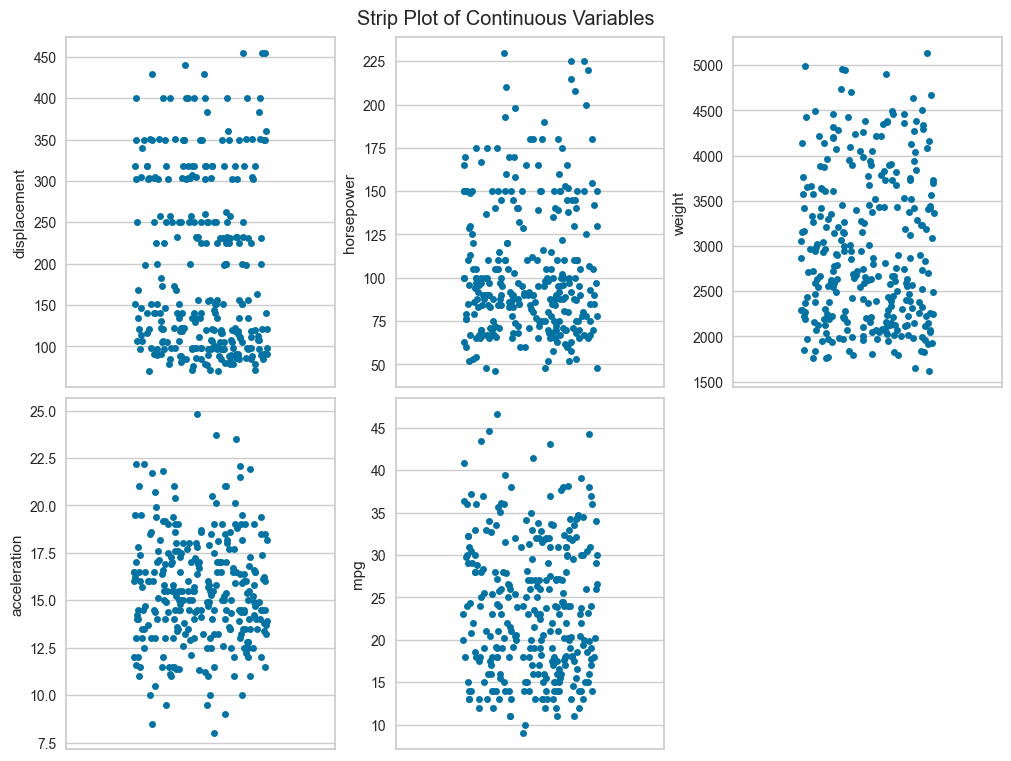

In [65]:
# setup plot figure for continuous variables visualization
width, height = 10, 7.5
plt.figure(figsize=(width, height), layout="constrained")
plt.suptitle("Strip Plot of Continuous Variables")

# subset variables with continuous data type from numerical variables
discrete_columns = ["cylinders", "model_year"]
continuous_train = numerical_train.drop(columns=discrete_columns)

# plot visualization for continuous variables
start_enumerate = 1
nrows, ncols = 2, 3
jitter = 0.25
for count, column in enumerate(continuous_train, start_enumerate):
    plt.subplot(nrows, ncols, count)
    sns.stripplot(continuous_train, y=column, jitter=jitter)
    plt.xticks([])

*[Strip plot](https://seaborn.pydata.org/tutorial/categorical.html#categorical-tutorial) digunakan untuk menunjukkan data points berdasarkan continuous numerical variables dalam Auto MPG dataset.*
* *Each dot represent the observation of car samples in Auto MPG dataset.*
* *Karena jumlah observasi dalam dataset dalam rentang ratusan dan relatif banyak, maka `jitter` with a certain value diterapkan untuk memvisualkan data points tersebut secara non-overlapping semaksimal mungkin.*

Beberapa insight dapat ditarik dari visualisasi sederhana ini seperti persebaran data, skewness, hingga distribution gaps. Namun fokus analisa kali ini untuk mendeteksi keberadaan [outlier](https://en.wikipedia.org/wiki/Outlier) pada tiap variabel:
* Dapat dilihat keberadaan clouds of data points seperti pada variabel `displacement & horsepower` yang menandakan adanya [modality](https://en.wikipedia.org/wiki/Mode_(statistics)) of continuous values pada rentang nilai di $y$-axis yang membentuk clouds tersebut.
* Ambil contoh variabel `horsepower`, tampak adanya data point on the upper extremity of the plot, yang merepresentasikan nilai `max (230)` dari variabel tersebut sebagaimana yang telah ditemukan pada bagian sebelumnya dan nilainya berada cukup jauh dari mode of the variable.
* Perlu diperhatikan bahwa extreme value ini tidak jauh berbeda dengan data points di sekitarnya, dan bukanlah sebuah error sebagaimana yang disampaikan pada [Initial Data Inspection](#initial-data-inspection), sehingga ia dapat didefinisikan sebagai *non-outlier*.

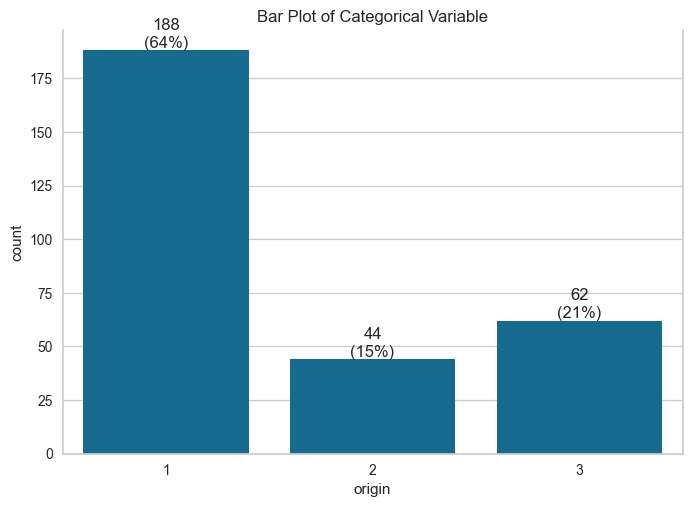

In [66]:
# plot visualization for categorical variables
multiply_percent = 100
axis_columns = 1
data_barplot = pd.concat([
    data_train["origin"].value_counts().sort_index(),
    data_train["origin"].value_counts(normalize=True).mul(multiply_percent)
], axis=axis_columns)
axes = sns.barplot(data_barplot, x=data_barplot.index, y="count")

proportion_index, barplot_index = 1, 0
labels = [
    f"{round(value.get_height())}\n({round(data_barplot.iloc[index, proportion_index])}%)"
    for index, value in enumerate(axes.containers[barplot_index])
]
axes.bar_label(axes.containers[barplot_index], labels=labels)
axes.spines.top.set_visible(False)

plt.title("Bar Plot of Categorical Variable")
plt.show()

*[Bar chart](https://en.wikipedia.org/wiki/Bar_chart) is a chart that presents categorical data with rectangular bars with heights or lengths proportional to the values that they represent.*
* *One axis of the chart shows the specific categories being compared, and the other axis represents a measured value.*
* *Categorical variables are those which values are selected from a group of categories—also called labels.*
* *Tiap grafik dalam plot di atas merepresentasikan labels yang berada dalam variabel tertentu dan occurences (count) dari label tersebut.*
* *Ambil contoh pada variabel `origin`, labels dengan occurences tertinggi adalah `1` sejumlah `183` observations atau `62%` dari keseluruhan data.*

Berdasarkan visualisasi ini, *tidak terdeteksi any particular issue* with the only categorical feature in Auto MPG dataset
* The variable `origin` contains only 3 labels; a definite small number of cardinality
* Meskipun label `1` dari variabel ini mendominasi dengan `64%` frekuensi, tetapi label `2` dan `3` lainnya cukup sering ditemukan dengan masing-masing mencakup `15%` dan `21%` dari keseluruhan data.

### Multivariate EDA

*[Multivariate analysis](https://en.wikipedia.org/wiki/Multivariate_statistics) encompasses the simultaneous observation and analysis of more than one variables, in order to understand the relationships between them and their relevance to the problem being studied. It may also determine to what extent it becomes easier to know and predict a value for one variable (possibly a dependent variable) if the value of the other variable (possibly the independent variable) is known.*

#### Discrete-Dependent Relationship

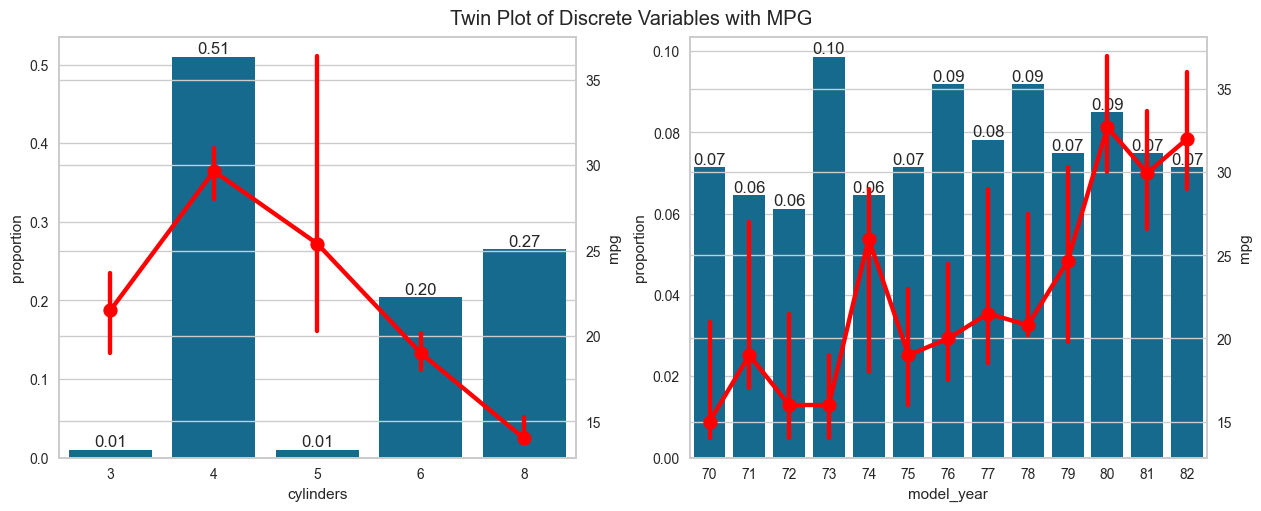

In [67]:
# setup plot figure for discrete variables visualization
width, height = 12.5, 5
plt.figure(figsize=(width, height), layout="constrained")
plt.suptitle("Twin Plot of Discrete Variables with MPG")

# subset variables with discrete data type from numerical variables
dependent_column = "mpg"
continuous_columns = continuous_train.drop(columns=dependent_column).columns
discrete_dependent_train = numerical_train.drop(columns=continuous_columns)

# plot visualization for discrete variables
nrows, ncols = 1, 2
for count, column in enumerate(discrete_dependent_train, start_enumerate):
    if column != dependent_column:
        plt.subplot(nrows, ncols, count)
        kwargs = {"data": discrete_dependent_train, "x": column}

        axes = sns.countplot(**kwargs, stat="proportion")
        axes.bar_label(axes.containers[0], fmt='%.2f')

        axes_twinx = axes.twinx()
        sns.pointplot(
            **kwargs,
            y=dependent_column,
            estimator="median",
            errorbar="ci",
            seed=rng,
            color="red",
            ax=axes_twinx,
        )

Visualisasi di atas terdiri dari 2 komponen:
1. [Count plot](https://seaborn.pydata.org/generated/seaborn.countplot.html) shows counts of observations in each discrete values using bars.
    * Instead of counts, `proportion` digunakan to show percentages of labels in `cylinders` and `model_year`.
    * Proportion of labels in `model_year` are comparable —ranging from `0.06` or 6% up to 10%.
    * The same cannot be said for `cylinders`: city-cycle with `4` cylinders represents 51% of the whole Auto MPG dataset, while `3 & 5` **rarely observed** with only 1% for each of them.
2. [Point plot](https://seaborn.pydata.org/generated/seaborn.pointplot.html) represents an estimate of central tendency for the discrete numerical variables by the position of the dot and provides some indication of the uncertainty around that estimate using [error bars](https://seaborn.pydata.org/tutorial/error_bars.html).
    * *The central tendencies for both variables are also defined according to insights found on [Section 2: Statistical Analysis](#statistical-analysis).*
    * *Confidence interval `ci` implemented to exhibit the range of likely values for the true population parameter (`median`) over random samples in Auto MPG.*
    * Median MPG shows an overall upward trend in `model_year`, although not perfectly linear. Analisis berikutnya akan melihat apakah pola serupa terjadi pada variabel lainnya.
    * On the contrary, the median generally decreases as cylinder count increases from `4-8`. With the exception for `3 & 5` cylinders: these cars have tiny sample size, resulting in the unstable estimates (wider `mpg` interval).

For values that are over-represented in the dataset, they tend to dominate the outcome. More specifically:
* A number of infrequent values adds noise with little information, therefore causing over-fitting.
    * Replacing of those labels by either the most frequent value or merging rare values together may be done. But ideally, evaluating the distribution of values within the rares and frequent value should be performed beforehand.
    * Meskipun proporsi `3 & 5` values are similar, perbedaan yang cukup signifikan dapat dilihat dari rentang interval `mpg` dari kedua nilai tersebut, apalagi jika dibandingkan dengan the frequent value of `4` cylinders.
* Rare values may be present in training set, but not in test set, which also causes overfitting to the train set.
    * Conversely, rare values may only appear in test set. thus, the machine learning model will not know how to evaluate it.

***Addendum: Rare Values Treatment***

In [68]:
class DropValues(BaseEstimator, TransformerMixin):
    """DropValues class for removing specified values from a given column in a DataFrame.
    
    This transformer is designed to be used with scikit-learn's pipeline 
    and allows for the removal of rows in a DataFrame where the specified column contains certain values.
    
    Attributes:
        column (str): The name of the column from which to drop values.
        values (list): A list of values to be removed from the specified column.
    
    Methods:
        fit(X, y=None):
            Fits the transformer to the data. This method is a no-op for this transformer.
    
        transform(X):
            Removes rows from the DataFrame where the specified column contains any of the values to be dropped.
    
    Args:
        column (str): The name of the column to process.
        values (str or list): The value(s) to drop from the specified column. Can be a single value or a list of values.
    """
    def __init__(self, column, values):
        self.column = column
        self.values = values if isinstance(values, list) else [values]

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        mask = ~X[self.column].isin(self.values)
        return X.loc[mask]

Untuk mengatasi permasalahan noisy rare values of `3 & 5` in `cylinders` variable, custom `DropValues` transformer class digunakan dan rare values tersebut tidak disertakan dalam bagian pemodelan berikutnya.

In [69]:
# discard rare values from "cylinders" variable in dataset
rare_variable, rare_values = "cylinders", [3, 5]
dropper = DropValues(rare_variable, rare_values)
data_cleaned = pd.DataFrame(dropper.fit_transform(data_cleaned))

rare_counts = data_cleaned[rare_variable].value_counts()
pd.DataFrame(rare_counts)

,count
cylinders,
4,199
8,103
6,83


* Tabel di atas menampilkan unique labels serta jumlah pada `cylinders` setelah removing rare values from the variable.
* Kemudian another train-test split dilakukan untuk mempersiapkan dataset menuju feature engineering.

In [70]:
# repeat split after discarding rare values
data_train, data_test = train_test_split(data_cleaned, random_state=rng)

#### Correlation Analysis

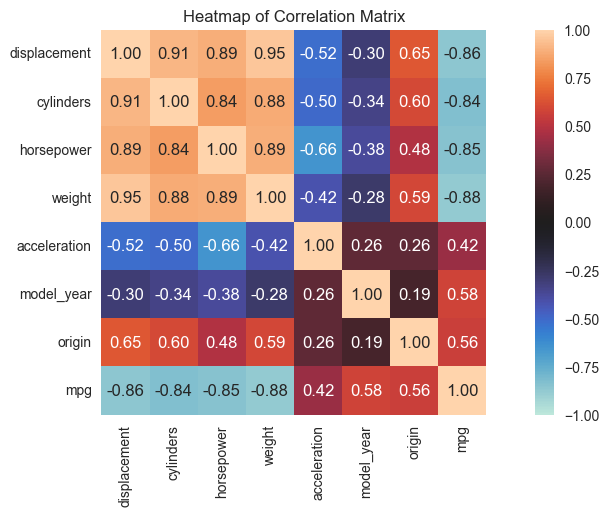

In [71]:
# calculate & visualize correlation of variables
associations_result = associations(
    data_train,
    num_num_assoc="spearman",
    nom_num_assoc="correlation_ratio",
    figsize=(width, height),
    title="Heatmap of Correlation Matrix"
)

associations_result["ax"]
plt.show()

*Heatmap di atas merupakan visualisasi dari pairwise [correlation matrix](https://en.wikipedia.org/wiki/Correlation#Correlation_matrices) between features in `data_train`, using:*
* *[Spearman's R](https://en.wikipedia.org/wiki/Spearman's_rank_correlation_coefficient) to measure monotonicity between numerical variables, and*
* *[Correlation ratio](https://en.wikipedia.org/wiki/Correlation_ratio) to assess linear/curvilinear relationship between nominal (categorical) and numerical variables.*

In general, what needs to be highlighted here is the cluster of near-perfect positive coefficient in the top left of the plot from `displacement` up to `weight` in both axes.
* Meaning all data points with greater $x$-axis values than that of a given data point will have greater $y$-axis values as well, and vice versa.
* This concerns machine learning methods yang menggunakan [permutation](https://scikit-learn.org/stable/modules/permutation_importance.html) technique. For example, permuting input variables to measure their importances produces unlikely data instances when two or more of them are correlated.
* Additional information provided through [Variance Inflation Factor](#linear-model-assumption) analysis below to gauge correlations beyond the pairwise relationships (multivariate).

#### Linear Model Assumption

In [72]:
endog = data_train["mpg"]
exog = sm.add_constant(pd.DataFrame(data_train).drop(columns="mpg"))

model = sm.OLS(endog, exog)
results = model.fit()

y_pred = results.fittedvalues
resid = results.resid
influence = results.get_influence()
resid_norm = influence.resid_studentized_internal
resid_norm_abs_sqrt = np.sqrt(np.abs(resid_norm))
leverage = influence.hat_matrix_diag

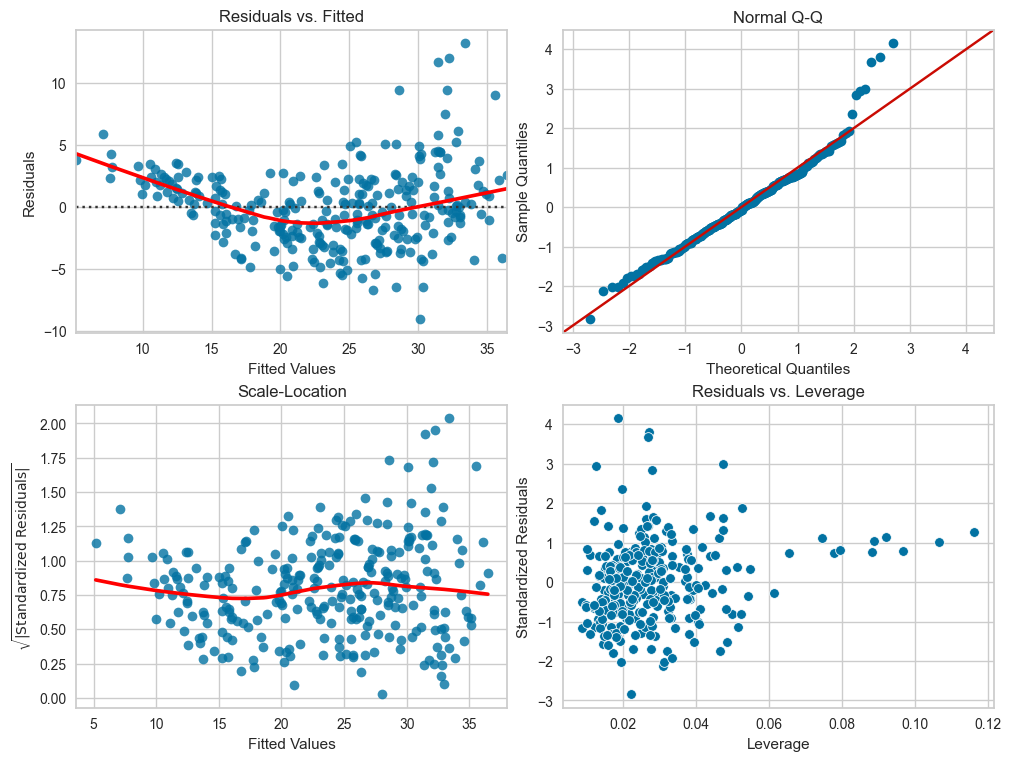

In [73]:
width, height = 10, 7.5
fig = plt.figure(figsize=(width, height), layout="constrained")
mosaic = [
    ["residuals", "qqplot"],
    ["scale_location", "influence"]
]
ax_dict = fig.subplot_mosaic(mosaic)

ax = sns.residplot(
    x=y_pred,
    y=resid,
    lowess=True,
    line_kws={"color": "red"},
    ax=ax_dict["residuals"],
)
ax.set_title("Residuals vs. Fitted")
ax.set_xlabel("Fitted Values")
ax.set_ylabel("Residuals")

sm.qqplot(resid_norm, line="45", ax=ax_dict["qqplot"])
ax_dict["qqplot"].set_title("Normal Q-Q")

ax = sns.regplot(
    x=y_pred,
    y=resid_norm_abs_sqrt,
    lowess=True,
    line_kws={"color": "red"},
    ax=ax_dict["scale_location"]
)
ax.set_title("Scale-Location")
ax.set_xlabel("Fitted Values")
ax.set_ylabel("$\\sqrt{|\\text{Standardized Residuals}|}$", fontsize=10)

ax = sns.scatterplot(
    x=leverage,
    y=resid_norm,
    ax=ax_dict["influence"],
)
ax.set_title("Residuals vs. Leverage")
ax.set_xlabel("Leverage")
ax.set_ylabel("Standardized Residuals")

plt.show()

* This is primarily true for simple regression. With many variables, you would do best to look at plots of the residuals vs each X variable or at added variable plots to detect a misspecified functional form. If you have 5 X variables and X3 has a quadratic relationship, that won't show up well in the residuals vs fitted plot.
* John Fox (1), in his booklet on regression diagnostics is rather cautious when it comes to giving numerical thresholds. He advises the use of graphics and to examine in closer details the points with "values of D that are substantially larger than the rest". According to Fox, thresholds should just be used to enhance graphical displays. (1) Fox, John. (1991). Regression Diagnostics: An Introduction. Sage Publications.
* A point with high leverage makes coefficient changes larger for the same residual size; high leverage increases sensitivity of parameter estimates to that point
* In the process of investigating normality (eg using q-q plots) it may become apparent that there are occasional extreme outlier observations (part of the process that you are studying) that will grossly affect ordinary predictive models. In such cases it would be prudent to use a predictive model that minimizes something other than squared errors, such as median regression, or (the negative of) a likelihood function that assumes heavy-tailed distributions. Similarly, you should evaluate predictive ability in such cases using something other than squared errors.

In [74]:
shape_column = 1
pd.DataFrame({
    "VIF": [
        variance_inflation_factor(pd.DataFrame(exog).values, i)
        for i in range(exog.shape[shape_column])
    ],
}, index=pd.DataFrame(exog).columns)

,VIF
const,764.113860
displacement,22.482580
cylinders,10.281408
horsepower,10.324767
weight,13.357581
acceleration,2.746953
model_year,1.242756
origin,1.704614


In [75]:
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.832
Model:                            OLS   Adj. R-squared:                  0.828
Method:                 Least Squares   F-statistic:                     198.6
Date:                Tue, 25 Aug 2026   Prob (F-statistic):          1.18e-104
Time:                        08:31:01   Log-Likelihood:                -740.65
No. Observations:                 288   AIC:                             1497.
Df Residuals:                     280   BIC:                             1527.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const          -11.2207      5.232     -2.145   

### Analysis Summary

| Anomaly | Description |
| --- | --- |
| Variable Magnitude | Terdeteksi adanya perbedaan magnitude antar numerical variables |
| Rare Values | Teridentifikasi nilai `3 & 5` memiliki proporsi yang jauh lebih rendah dibandingkan nilai lainnya pada variabel `cylinders` |

---

## Section 3 | Predictive Modeling

In [76]:
# import required libraries
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    make_scorer,
    mean_absolute_error,
    r2_score,
)
from sklearn.model_selection import GridSearchCV, KFold, cross_validate
from sklearn.pipeline import make_pipeline
from yellowbrick.model_selection import LearningCurve
from yellowbrick.regressor import PredictionError, ResidualsPlot

### Model Construction

In the early modeling phase, various machine learning techniques are applied to build predictive or descriptive models toward the prepared data. The goal is to develop a model (or set of models) that accurately represents the patterns in the data and meets the objectives.

#### Modeling ETL

In [77]:
def feature_target_split(dataset, random_state, column_target="mpg"):
    X = pd.DataFrame(dataset).drop(columns=column_target)
    y = pd.Series(dataset[column_target])
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=random_state)

    return X_train, X_test, y_train, y_test

*In machine learning:*
* *Features are the input variables (independent variables) used to make predictions, while*
* *The target is the variable to be predicted or understood (dependent variable).*
* *Together, they form the basis for supervised learning, where features map to a target value. Features are selected for relevance, and the target is the goal.*

In [78]:
# split features and target to random train and test subsets
X_train, X_test, y_train, y_test = feature_target_split(data_cleaned, rng)

# perform dimensionality analysis of train-test subsets
inspect_dimensionality(data_cleaned, X_train, X_test)

,row_n,row_ratio,column
dataset,385,1.000000,8
train,288,0.748052,7
test,97,0.251948,7


Proses splitting di atas kurang lebih serupa dengan yang telah dilakukan pada [Section 2: Train-Test Split](#train-test-split), dengan beberapa perbedaan:
* `feature_target_split` membagi `data` menjadi 2 pasang `X_train - X_test` dan `y_train - y_test`.
* Proporsi pembagian dataset ini tetap sama, namun karena target variabel `mpg` turut dipisahkan menjadi `y_train & y_test`, jumlah kolom pada `train & test`—dengan kata lain, `X_train & X_test`—berkurang 1 variabel.

In [79]:
def modeling_etl(id, random_state):
    """Modeling ETL process for data preparation.
    
    This function performs an Extract, Transform, Load (ETL) process on the dataset identified by the given ID.
    It includes steps to drop missing data, match categories, and drop specific values from the dataset.
    The cleaned data is then split into training and testing features and targets.
    
    Args:
        id (int): The identifier for the dataset to be processed.
        random_state (int): The random state for reproducibility of the train-test split.
    
    Returns:
        tuple: A tuple containing:
            - train_features (DataFrame): The features for the training set.
            - test_features (DataFrame): The features for the testing set.
            - train_target (Series): The target variable for the training set.
            - test_target (Series): The target variable for the testing set.
    """
    drop_missing = DropMissingData()
    match = MatchCategories(unmatched_variable, ignore_format=True)
    drop_values = DropValues(rare_variable, rare_values)
    pipeline = make_pipeline(drop_missing, match, drop_values)

    data = data_etl(id)
    data_cleaned = pipeline.fit_transform(data)
    
    train_features, test_features, train_target, test_target = feature_target_split(data_cleaned, random_state)

    return train_features, test_features, train_target, test_target

In [80]:
# extract, transform, and load data for modeling
X_train, X_test, y_train, y_test = modeling_etl(id_auto_mpg, rng)

#### Modeling Pipeline

In [81]:
def modeling_pipeline(
    learning_rate,
    max_depth,
    min_samples_leaf,
):
    regressor = HistGradientBoostingRegressor(
        loss="absolute_error",
        learning_rate=learning_rate,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        early_stopping=True,
        scoring="neg_mean_absolute_error",
        random_state=rng,
    )

    return regressor

In [82]:
learning_rate=0.1
max_depth=None
min_samples_leaf=20

estimator = modeling_pipeline(
    learning_rate,
    max_depth,
    min_samples_leaf
)
estimator

,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'absolute_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""category"" are considered to be categorical features. The input must be an object exposing a ``__dataframe__`` method such as pandas or polars DataFrames to use this feature.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide ` and:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_categorical.py`... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged::

#### Hyperparameter Tuning

In [83]:
# setup hyperparameter grid space
param_name_learning_rate = "learning_rate"
start, stop, num = -3, -1, 3
param_range_learning_rate = np.logspace(start, stop, num)

param_name_max_depth = "max_depth"
param_range_max_depth = range(1, 4)

param_name_min_samples_leaf = "min_samples_leaf"
start, stop, num = min_samples_leaf // 4, min_samples_leaf, 3
param_range_min_samples_leaf = np.geomspace(start, stop, num, dtype=int)

param_grid = {
    param_name_learning_rate: param_range_learning_rate,
    param_name_max_depth: param_range_max_depth,
    param_name_min_samples_leaf: param_range_min_samples_leaf
}

Learning Rate:
* Start with a moderate rate: Initialize your model with a standard default like 0.1 or 0.05 while tuning other tree structure parameters (like max_depth or subsample).
* Lower and scale up: Once the structural parameters are set, lower the learning rate (e.g., to 0.01) and proportionally increase n_estimators using early stopping to find the exact point where validation loss stops improving.

Unlike bagging and random forests, boosting
can overfit if B is too large, although this overfitting tends to occur
slowly if at all.

Often d = 1 works well, in which case each
tree is a stump, consisting of a single split. In this case, the boosted stump
ensemble is fitting an additive model, since each term involves only a
single variable.

In [84]:
# generate scorer from defined loss function
scoring = {
    "neg_mae": make_scorer(mean_absolute_error, greater_is_better=False),
    "r2": make_scorer(r2_score)
}

In [85]:
# setup cross-validation methods
n_splits_inner, n_splits_outer = 6, 12
kwargs = {"shuffle": True, "random_state": rng}
inner_cv, outer_cv = KFold(n_splits_inner, **kwargs), KFold(n_splits_outer, **kwargs)

* We chose to perform six-fold cross-validation because 288 is an exact multiple of six.

In [86]:
# perform hyperparameter search over nested cross-validation procedure
n_jobs = -1
metric_optimized = "neg_mae"
search = GridSearchCV(
    estimator,
    param_grid=param_grid,
    scoring=scoring,
    n_jobs=n_jobs,
    refit=metric_optimized,
    cv=inner_cv
)

In [87]:
# fit model with the best hyperparameters over the train set
search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",HistGradientB...solute_error')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': array([0.001, 0.01 , 0.1 ]), 'max_depth': range(1, 4), 'min_samples_leaf': array([ 5, 10, 20])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'neg_mae': make_scorer(m...hod='predict'), 'r2': make_scorer(r...hod='predict')}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'neg_mae'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: intContro

### Model Inspection

#### Evaluation Metrics

In [88]:
# hyperparameters grid space
df_params = pd.DataFrame({
    "learning_rate": [param_range_learning_rate],
    "max_depth": [tuple(param_range_max_depth)],
    # "max_iter": [param_range_max_iter],
    "min_samples_leaf": [param_range_min_samples_leaf]
}, index=["grid_params"])

# chosen hyperparameters from inner_cv
df_cv_params = pd.DataFrame(
    [(search.cv_results_["params"][search.best_index_])],
    index=["best_params"]
)

pd.concat([df_params, df_cv_params]).transpose()

,grid_params,best_params
learning_rate,"[0.001, 0.01, 0.1]",0.1
max_depth,"(1, 2, 3)",3
min_samples_leaf,"[5, 10, 20]",20


In [89]:
# cross-validated scores from outer_cv
cv_scores = cross_validate(
    search.best_estimator_, X_train, y_train,
    scoring=scoring,
    cv=outer_cv,
    n_jobs=-1,
)
df_cv = pd.DataFrame({
    "mae": [abs(np.mean(cv_scores["test_neg_mae"])), np.std(cv_scores["test_neg_mae"])],
    "r2": [np.mean(cv_scores["test_r2"]), np.std(cv_scores["test_r2"])]
}, index=["mean", "std"])

# test scores from best estimator fitted on train set
y_pred = pd.Series(
    search.best_estimator_.predict(X_test),
    index=y_test.index,
    name="mpg_pred"
)
df_pred = pd.DataFrame({
    "mae": [mean_absolute_error(y_test, y_pred)],
    "r2": [r2_score(y_test, y_pred)]
})

multiindex_tuples = [
    ('cv_scores', 'mean'),
    ('cv_scores', 'std'),
    ('test_scores', '')
]
multiindex = pd.MultiIndex.from_tuples(multiindex_tuples)
pd.concat([df_cv, df_pred]).set_index(multiindex)

mae        r2
cv_scores   mean  1.957252  0.871568
            std   0.349941  0.060472
test_scores       1.901461  0.871577

#### Early Stopping Curve

In [90]:
train_errors, test_errors = [], []

for i, (train_pred, test_pred) in enumerate(
    zip(
        search.best_estimator_.staged_predict(X_train),
        search.best_estimator_.staged_predict(X_test),
    )
):
    train_errors.append(mean_absolute_error(y_train, train_pred))
    test_errors.append(mean_absolute_error(y_test, test_pred))

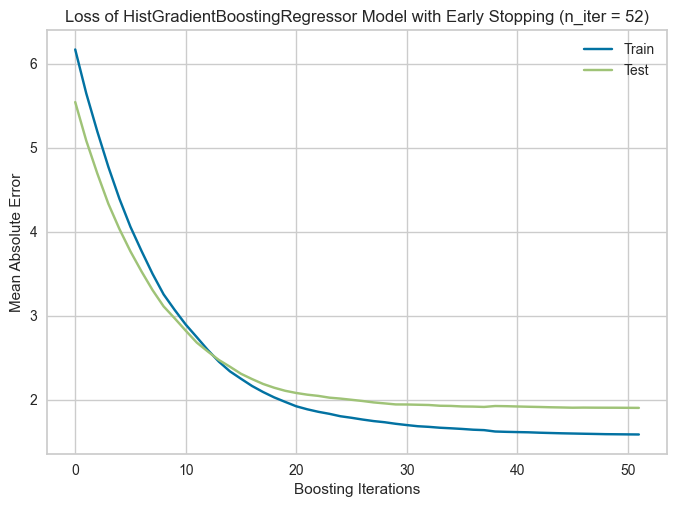

In [91]:
sns.lineplot(train_errors, label="Train")
sns.lineplot(test_errors, label="Test")

plt.title(f"Loss of HistGradientBoostingRegressor Model with Early Stopping (n_iter = {search.best_estimator_.n_iter_})")
plt.xlabel("Boosting Iterations")
plt.ylabel("Mean Absolute Error")
plt.show()

#### Learning Curve

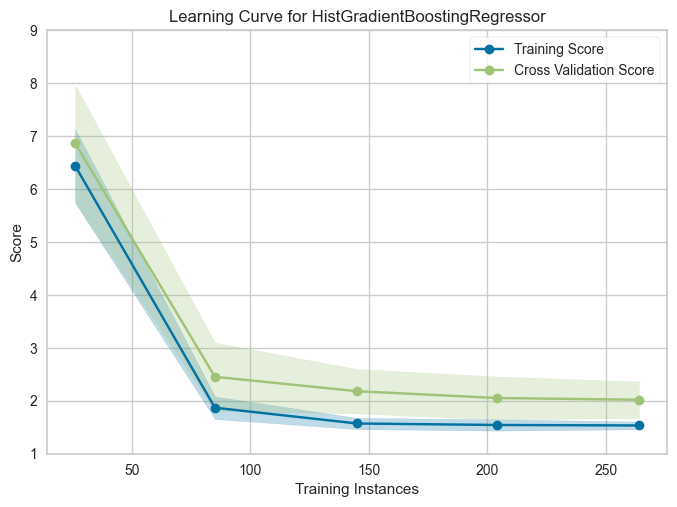

In [92]:
# visualize learning curve of the model
visualizer = LearningCurve(
    estimator=search.best_estimator_,
    cv=outer_cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    shuffle=True,
    random_state=rng,
    force_model=True
)
visualizer.fit(X_train, y_train)

visualizer.ax.yaxis.set_inverted(True)
yticks = visualizer.ax.get_yticks()
visualizer.ax.yaxis.set_ticks(yticks, labels=[f"{abs(ytick):.0f}" for ytick in yticks])

visualizer.finalize()

#### Prediction Error

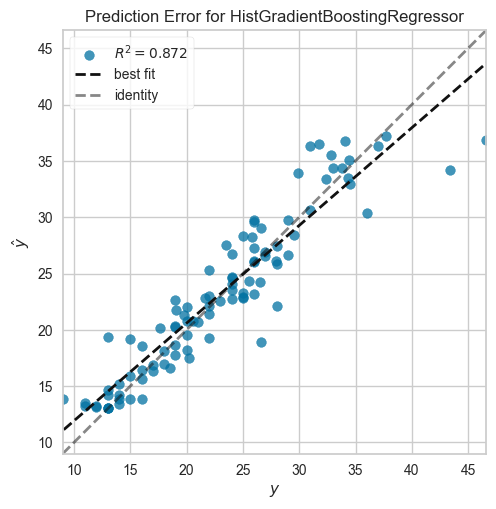

In [93]:
# visualize prediction error of the model
visualizer = PredictionError(search.best_estimator_, force_model=True)
visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test) # coefficient of determination score on test set
visualizer.finalize()

legend_texts = visualizer.ax.get_legend().get_texts()
items_first_index, items_first_text = 0, "R^2"
legend_texts[items_first_index].set_text(f"${items_first_text} = {visualizer.score_:.3f}$")

#### Residuals Plot

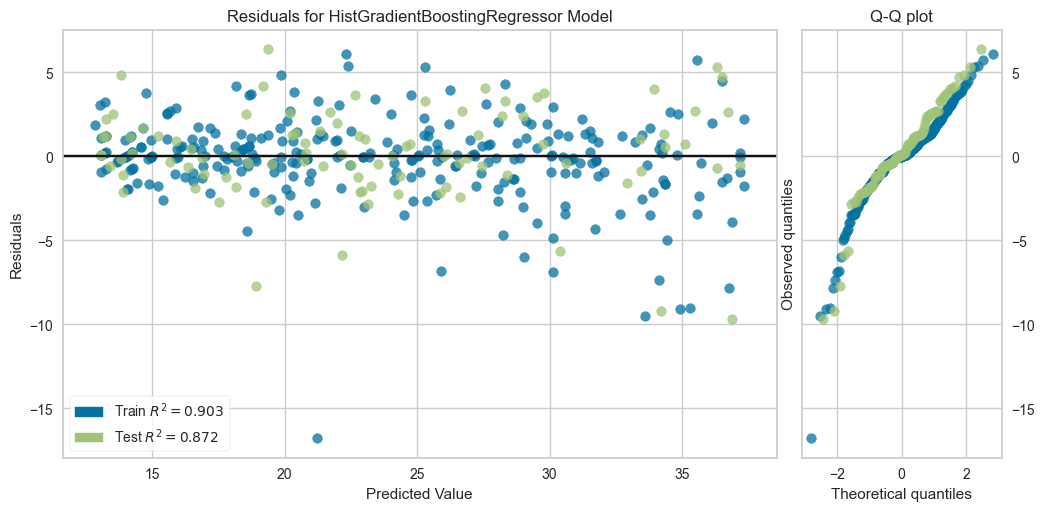

In [94]:
# plot residuals of the model against the predicted values
width, height = 10, 5
_, ax = plt.subplots(figsize=(width, height), layout="constrained")

visualizer = ResidualsPlot(
    search.best_estimator_,
    ax=ax,
    hist=False, # disable histogram of residuals as prerequisite for enabling QQ plot
    qqplot=True, 
    force_model=True
)

visualizer.fit(X_train, y_train)
visualizer.score(X_test, y_test)
visualizer.finalize()

In [95]:
y_pred_train = pd.Series(
    search.best_estimator_.predict(X_train),
    index=pd.Series(y_train).index,
    name="mpg_pred"
)
resid_train = pd.Series(
    y_pred_train - y_train,
    index=pd.Series(y_train).index,
    name="resid"
)
eval_train = pd.concat(
    [data_train, y_pred_train, resid_train],
    axis=1
)

resid_min_cond = resid_train == resid_train.min()
eval_train.loc[pd.Series(resid_train[resid_min_cond]).index]

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg,mpg_pred,resid
387,262.0,6.0,85.0,3015.0,17.0,82.0,1,38.0,21.224163,-16.775837


If we find any **systematic** deviations from the expected behavior, they may signal an issue with a model
* For instance, an omitted explanatory variable or a wrong functional form of a variable included in the model
* Is it a truly rare but valid observation? If a real but extreme case: keep it, but report it

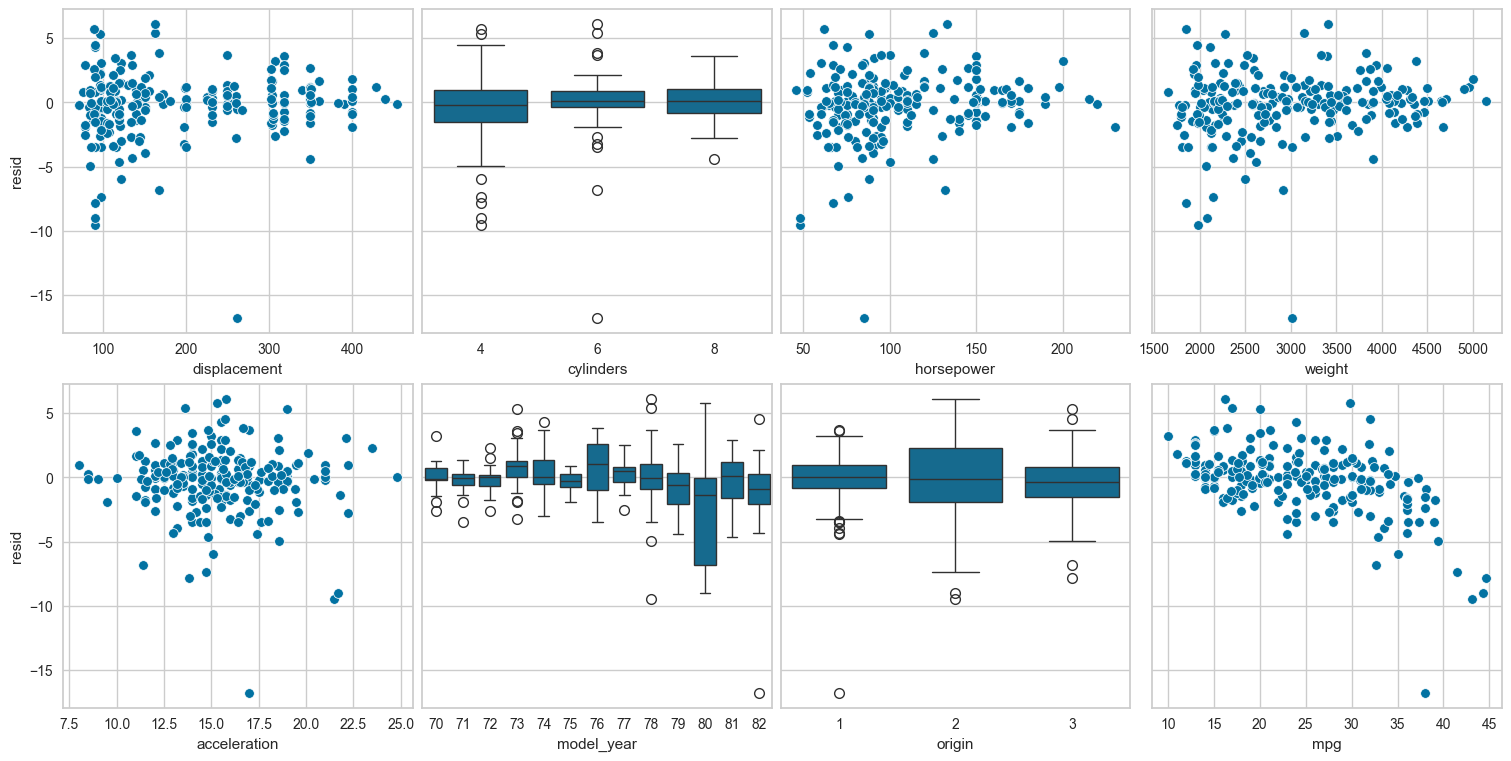

In [96]:
width, height = 15, 7.5
nrows, ncols = 2, 4
_, axes = plt.subplots(
    nrows, ncols,
    figsize=(width, height),
    sharey=True,
    layout="constrained",
)

boxplot_columns = discrete_columns.copy()
boxplot_columns.append("origin")
for count, column in enumerate(data_train):
    ax = axes.flat[count]

    if column not in boxplot_columns:
        sns.scatterplot(
            x=data_train[column],
            y=resid_train,
            ax=ax,
        )
    else:
        ax = sns.boxplot(
            x=data_train[column],
            y=resid_train,
            ax=ax,
        )
        ax.xaxis.set_ticks(
            ticks=ax.get_xticks(),
            labels=pd.Series(data_train[column].unique()).sort_values()
        )

* The reference line at 0 emphasizes that the residuals are randomly split about 50-50 between positive and negative. Hence, no systematic patterns apparent here.
* However, the range of residuals observed during rush hours is significantly wider than that of non-peak hours. This observation is logical since the demand for bike sharing is much higher during rush hours compared to non-peak hours, making predictions during rush hours relatively more challenging.

---

* Recommendation: monotonic constraints, quantile loss, max_features regularization